<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/string_theory/string_ch05_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*String Theory* — `string_ch05_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# String Theory Ch 5 — Figure Notebook
**Polyakov Path Integral and Ghosts**

In [1]:
FIG_DIR = 'figures/ch05'

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

BG='#1e1e2e';FG='#cdd6f4';EDGE='#45475a'
SKYB='#89c4f4';YELL='#f9c74f';GREEN='#90ee90'
RED='#e07070';PURP='#c792ea';ORAN='#e8a838';TEAL='#2ec4b6'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,
    'text.color':FG,'axes.labelcolor':FG,
    'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.25,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':SKYB,'legend.framealpha':0.3,
    'legend.edgecolor':EDGE,'lines.linewidth':2.2,
    'axes.linewidth':1.2,'figure.dpi':110,
})
os.makedirs(FIG_DIR, exist_ok=True)

def save(name, fig):
    fig.savefig(f'{FIG_DIR}/{name}', dpi=150, bbox_inches='tight', facecolor=BG)
    plt.show(); print(f'Saved: {FIG_DIR}/{name}')

print('Setup complete.')


Setup complete.


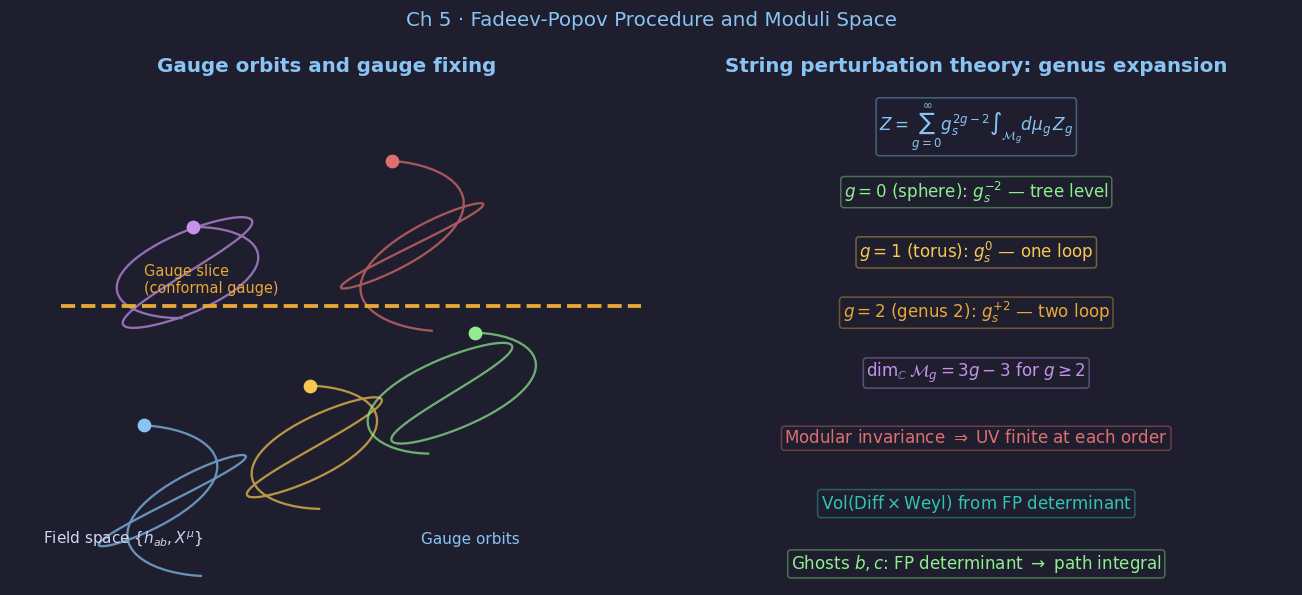

Saved: figures/ch05/fig01_fadeev_popov.png


In [2]:

# ── fig01: Fadeev-Popov and moduli ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle('Ch 5 · Fadeev-Popov Procedure and Moduli Space', color=SKYB, fontsize=13)

# Left: gauge orbit picture
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title('Gauge orbits and gauge fixing', color=SKYB)
ax.set_xlim(-0.3, 3.5); ax.set_ylim(-0.3, 3.5); ax.axis('off')

rng = np.random.default_rng(17)
# Gauge orbits (curves through field space)
for i, (x0, y0, col) in enumerate([(0.5,0.5,SKYB),(1.5,0.8,YELL),(2.5,1.2,GREEN),
                                     (0.8,2.0,PURP),(2.0,2.5,RED)]):
    # orbit: parametric curve
    t = np.linspace(0, 1, 100)
    dx = rng.uniform(-0.5, 0.5); dy = rng.uniform(-0.5, 0.5)
    xp = x0 + 0.4*np.sin(4*np.pi*t) + dx*t
    yp = y0 + 0.4*np.cos(3*np.pi*t) + dy*t
    ax.plot(xp, yp, color=col, lw=1.5, alpha=0.7)
    ax.plot(xp[0], yp[0], 'o', color=col, ms=8, zorder=6)

# Gauge-fixing surface (line)
ax.plot([0, 3.5], [1.8, 1.8], color=ORAN, lw=2.5, ls='--',
        label='Gauge slice')
ax.text(0.5, 1.9, 'Gauge slice\n(conformal gauge)', color=ORAN, fontsize=9.5)
ax.text(0.05, 0.08, r'Field space $\{h_{ab},X^\mu\}$', color=FG, fontsize=10,
        transform=ax.transAxes)
ax.text(0.65, 0.08, 'Gauge orbits', color=SKYB, fontsize=10,
        transform=ax.transAxes)

# Right: genus expansion
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title('String perturbation theory: genus expansion', color=SKYB)
items = [
    (0.5, 0.91, r'$Z=\sum_{g=0}^\infty g_s^{2g-2}\int_{\mathcal{M}_g}d\mu_g\,Z_g$', SKYB),
    (0.5, 0.78, r'$g=0$ (sphere): $g_s^{-2}$ — tree level', GREEN),
    (0.5, 0.66, r'$g=1$ (torus): $g_s^0$ — one loop', YELL),
    (0.5, 0.54, r'$g=2$ (genus 2): $g_s^{+2}$ — two loop', ORAN),
    (0.5, 0.42, r'$\dim_\mathbb{C}\mathcal{M}_g=3g-3$ for $g\geq 2$', PURP),
    (0.5, 0.29, r'Modular invariance $\Rightarrow$ UV finite at each order', RED),
    (0.5, 0.16, r'$\mathrm{Vol(Diff\times Weyl)}$ from FP determinant', TEAL),
    (0.5, 0.04, r'Ghosts $b,c$: FP determinant $\to$ path integral', GREEN),
]
for x_,y_,txt,col in items:
    ax2.text(x_,y_,txt,ha='center',va='center',fontsize=11,color=col,
             transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.4))

plt.tight_layout()
save('fig01_fadeev_popov.png', fig)


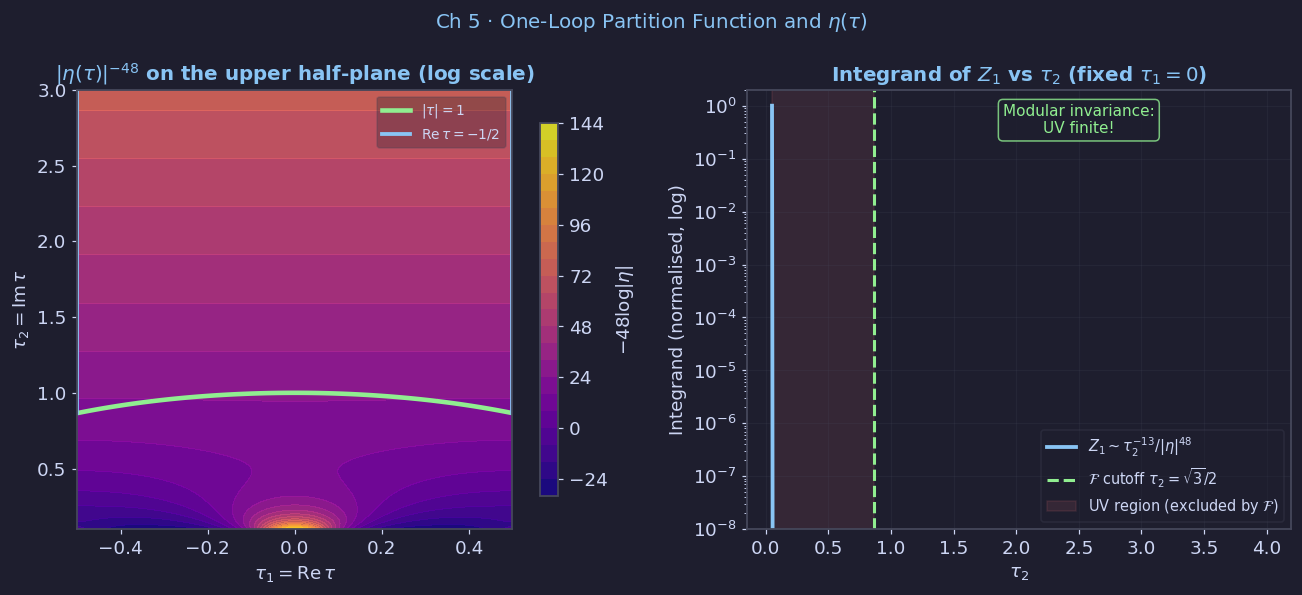

Saved: figures/ch05/fig02_partition_function_eta.png


In [3]:

# ── fig02: One-loop partition function and Dedekind eta ───────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle(r'Ch 5 · One-Loop Partition Function and $\eta(\tau)$',
             color=SKYB, fontsize=13)

# Left: Dedekind eta function |eta(tau)|^2 on upper half-plane
tau2_vals = np.linspace(0.1, 3.0, 300)
tau1_vals = np.linspace(-0.5, 0.5, 200)
T1, T2 = np.meshgrid(tau1_vals, tau2_vals)

# |eta(tau)|^2 = prod_{n=1}^inf |1-e^{2pi i tau}|^2 * e^{-pi*tau2/6}
# For large tau2: |eta| ~ e^{-pi*tau2/12}
# Compute numerically with finite product
def eta_abs2(tau1, tau2, Nmax=15):
    q = np.exp(2*np.pi*1j*(tau1 + 1j*tau2))
    result = np.abs(q)**(1/12)
    for n in range(1, Nmax+1):
        result *= np.abs(1 - q**n)**2
    return result

ETA2 = eta_abs2(T1, T2, Nmax=10)

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'$|\eta(\tau)|^{-48}$ on the upper half-plane (log scale)', color=SKYB)
log_eta = -48 * np.log(np.clip(ETA2, 1e-10, None))
cf = ax.contourf(tau1_vals, tau2_vals, log_eta, levels=25,
                 cmap='plasma', alpha=0.85)
plt.colorbar(cf, ax=ax, label=r'$-48\log|\eta|$', shrink=0.85)

# Fundamental domain boundary
theta_fd = np.linspace(np.pi*2/3, np.pi/3, 100)
ax.plot(np.cos(theta_fd), np.sin(theta_fd), color=GREEN, lw=3,
        label=r'$|\tau|=1$')
ax.plot([-0.5,-0.5],[np.sqrt(3)/2, 3.0], color=SKYB, lw=2.5,
        label=r'$\mathrm{Re}\,\tau=-1/2$')
ax.plot([ 0.5, 0.5],[np.sqrt(3)/2, 3.0], color=SKYB, lw=2.5)
ax.legend(fontsize=9, loc='upper right')
ax.set_xlabel(r'$\tau_1=\mathrm{Re}\,\tau$')
ax.set_ylabel(r'$\tau_2=\mathrm{Im}\,\tau$')

# Right: integrand vs tau2
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'Integrand of $Z_1$ vs $\tau_2$ (fixed $\tau_1=0$)',
              color=SKYB)
tau2_plot = np.linspace(0.05, 4.0, 400)
eta2_plot = eta_abs2(0.0, tau2_plot, Nmax=15)
integrand = tau2_plot**(-13) / (eta2_plot**24)
integrand_norm = integrand / integrand.max()

ax2.semilogy(tau2_plot, integrand_norm, color=SKYB, lw=2.5,
             label=r'$Z_1\sim\tau_2^{-13}/|\eta|^{48}$')
tau2_cutoff = np.sqrt(3)/2
ax2.axvline(tau2_cutoff, color=GREEN, lw=2, ls='--',
            label=r'$\mathcal{F}$ cutoff $\tau_2=\sqrt{3}/2$')
ax2.fill_between([0.05, tau2_cutoff], 1e-10, 1e2,
                 color=RED, alpha=0.12, label=r'UV region (excluded by $\mathcal{F}$)')
ax2.set_xlabel(r'$\tau_2$')
ax2.set_ylabel('Integrand (normalised, log)')
ax2.legend(fontsize=9.5)
ax2.grid(True, alpha=0.2)
ax2.set_ylim(1e-8, 2)
ax2.text(2.5, 0.3,
         r'Modular invariance:' + '\n' + r'UV finite!',
         ha='center', fontsize=10, color=GREEN,
         bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.8))

plt.tight_layout()
save('fig02_partition_function_eta.png', fig)


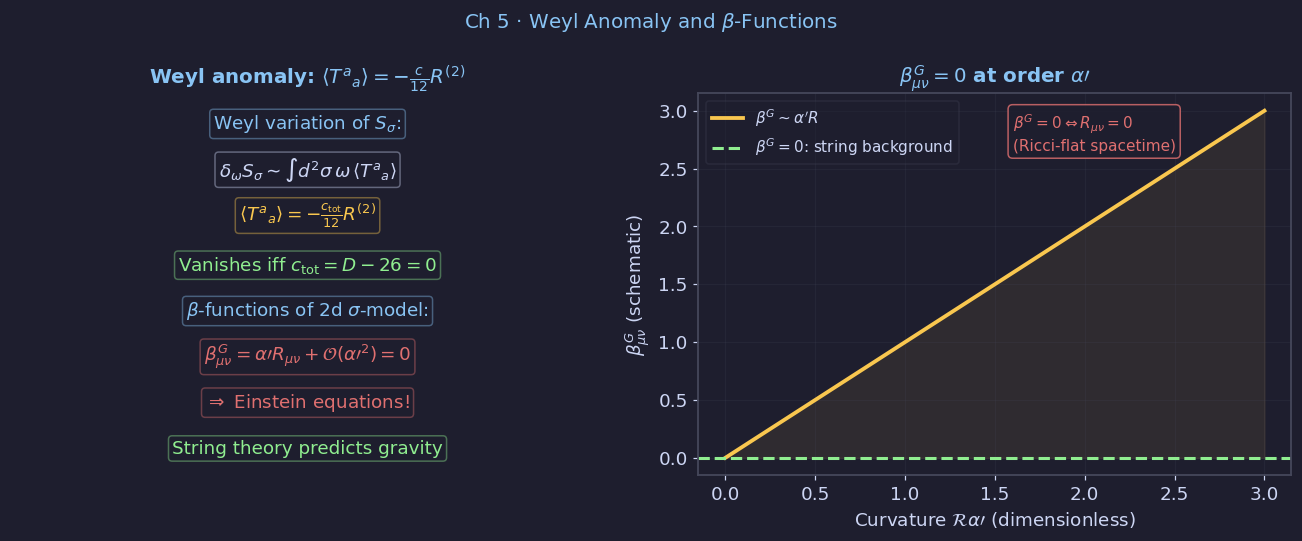

Saved: figures/ch05/fig03_weyl_anomaly.png


In [4]:

# ── fig03: Weyl anomaly and beta functions ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(r'Ch 5 · Weyl Anomaly and $\beta$-Functions',
             color=SKYB, fontsize=13)

ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r'Weyl anomaly: $\langle T^a{}_a\rangle=-\frac{c}{12}R^{(2)}$',
             color=SKYB)
items = [
    (0.5, 0.92, r'Weyl variation of $S_\sigma$:', SKYB),
    (0.5, 0.80, r'$\delta_\omega S_\sigma \sim \int d^2\sigma\,\omega\,\langle T^a{}_a\rangle$', FG),
    (0.5, 0.68, r'$\langle T^a{}_a\rangle=-\frac{c_{\rm tot}}{12}R^{(2)}$', YELL),
    (0.5, 0.55, r'Vanishes iff $c_{\rm tot}=D-26=0$', GREEN),
    (0.5, 0.43, r'$\beta$-functions of 2d $\sigma$-model:', SKYB),
    (0.5, 0.31, r'$\beta^G_{\mu\nu}=\alpha\prime R_{\mu\nu}+\mathcal{O}(\alpha\prime^2)=0$', RED),
    (0.5, 0.19, r'$\Rightarrow$ Einstein equations!', RED),
    (0.5, 0.07, r'String theory predicts gravity', GREEN),
]
for x_,y_,txt,col in items:
    ax.text(x_,y_,txt,ha='center',va='center',fontsize=12,color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.2',fc=BG,ec=col,alpha=0.4))

ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'$\beta^G_{\mu\nu}=0$ at order $\alpha\prime$', color=SKYB)
# Schematic: beta function of sigma model vs coupling (curvature)
R_curv = np.linspace(0, 3, 300)  # curvature scale / alpha'
beta_G = R_curv  # schematic: beta = alpha' R at leading order
ax2.plot(R_curv, beta_G, color=YELL, lw=2.5, label=r"$\beta^G\sim\alpha' R$")
ax2.axhline(0, color=GREEN, lw=2, ls='--', label=r'$\beta^G=0$: string background')
ax2.fill_between(R_curv, 0, beta_G, color=YELL, alpha=0.08)
ax2.set_xlabel(r'Curvature $\mathcal{R}\alpha\prime$ (dimensionless)')
ax2.set_ylabel(r'$\beta^G_{\mu\nu}$ (schematic)')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.2)
ax2.text(0.53, 0.85,
         r'$\beta^G=0 \Leftrightarrow R_{\mu\nu}=0$' + '\n(Ricci-flat spacetime)',
         transform=ax2.transAxes, fontsize=10, color=RED,
         bbox=dict(boxstyle='round', fc=BG, ec=RED, alpha=0.8))

plt.tight_layout()
save('fig03_weyl_anomaly.png', fig)


In [5]:
# ── Download all figures as a zip ────────────────────────────────────────
import shutil

shutil.make_archive('ch05_figures', 'zip', 'figures/ch05')

try:
    from google.colab import files
    files.download('ch05_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — figures saved to figures/ch05/')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
